# Filter Design
## FIR Filter

FIR-Filterentwürfe bestehen typischerweise aus Filtern mit einer Übergangsbreite sowie maximalen Ripple im Durchlass- und Sperrbereich, die bestimmte Grenzwerte nicht überschreiten. Zusätzlich zu diesen Entwurfsparametern muss die Filterordnung bzw. die Länge der abgeschnittenen Impulsantwort gewählt werden.

FIR-Filter sind stabil und können mit linearer Phase entworfen werden. Dennoch können sie lange Einschwingvorgänge aufweisen und in bestimmten Anwendungen rechnerisch aufwendig sein.


## Window Design
Die Filterung mit Window erfolgt durch eine Faltung im Frequenzbereich zwischen dem zu filternden Signal und der Frequenzantwort des gewählten Fenstertyps. Neben dem Typ wird das Fenster durch die Grenzfrequenz und die Ordnung definiert.

Die gebräuchlichsten Fenstertypen für Filter sind:
- Rechteckfenster (Rectangular Window)
- Hamming-Fenster
- Hann-Fenster
- Blackman-Fenster
- Bartlett-Fenster


**📝  Aufgabe 2: FIR Window Filter**

Für eine Grenzfrequenz von 350 Hz und eine Ordnung von 20, berechne und zeichne die Impulsantwort und die Fenster Koeffizienten für verschiedene Fensterfunktionen. Beschreibe die Unterschiede.

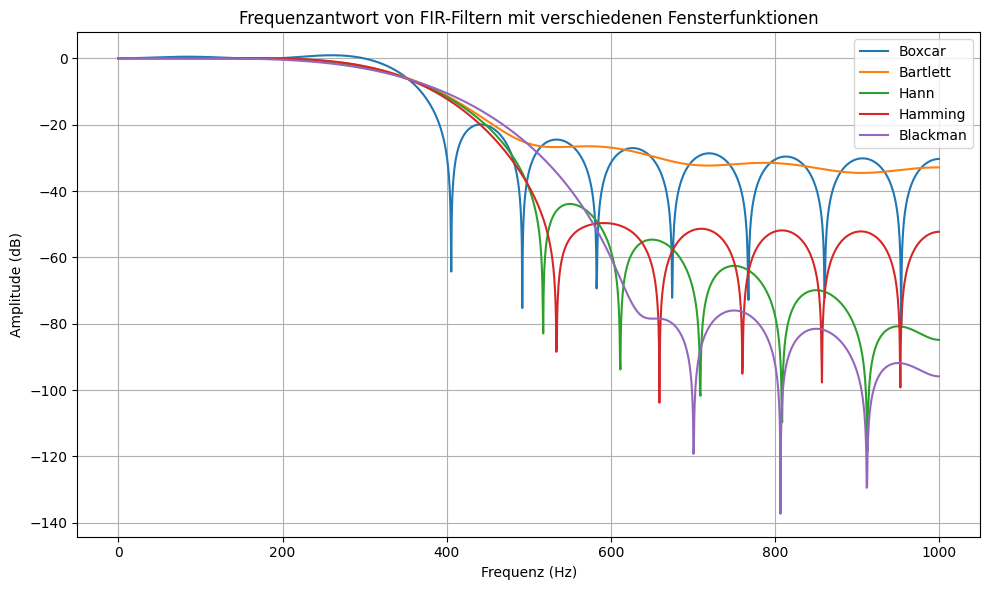

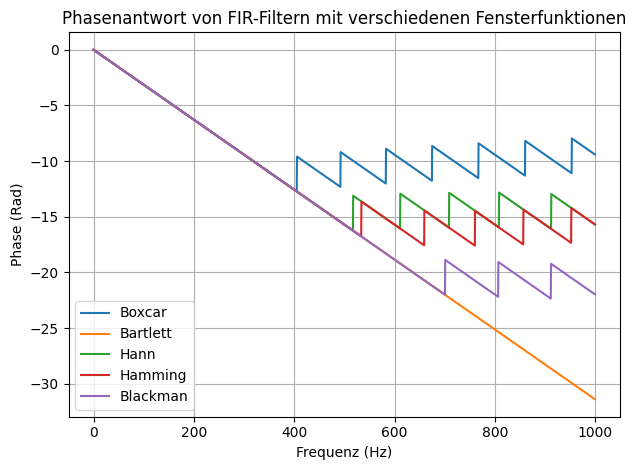

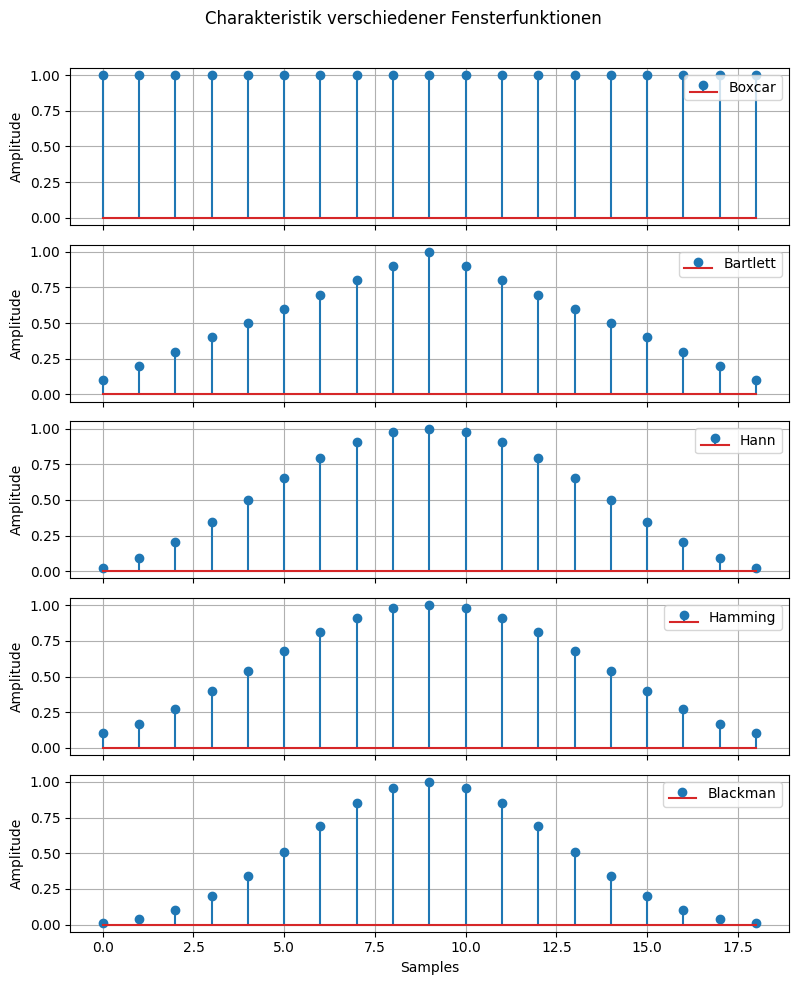

In [3]:
# Parameter
fc = 350       # Grenzfrequenz in Hz
order = 20     # Filterordnung
fs = 2000      # Abtastfrequenz in Hz

# Fensterarten
window_types = ['boxcar', 'bartlett', 'hann', 'hamming',  'blackman']

# Diagramm vorbereiten
plt.figure(figsize=(10, 6))

# Frequenzantwort für jedes Fenster berechnen und darstellen
for window_type in window_types:
    b = firwin(order + 1, fc, window=window_type, fs=fs)
    w, h = freqz(b, worN=2000, fs=fs)
    plt.plot(w, 20 * np.log10(np.abs(h)), label=window_type.capitalize())


# Diagramm formatieren
plt.title('Frequenzantwort von FIR-Filtern mit verschiedenen Fensterfunktionen')
plt.xlabel('Frequenz (Hz)')
plt.ylabel('Amplitude (dB)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Phasenantwort für jedes Fenster berechnen und darstellen
for window_type in window_types:
    b = firwin(order + 1, fc, window=window_type, fs=fs)
    w, h = freqz(b, worN=2000, fs=fs)
    plt.plot(w, np.unwrap(np.angle(h)), label=f'{window_type.capitalize()}')


# Diagramm formatieren
plt.title('Phasenantwort von FIR-Filtern mit verschiedenen Fensterfunktionen')
plt.xlabel('Frequenz (Hz)')
plt.ylabel('Phase (Rad)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Fensterarten

# Diagramm erstellen
fig, axs = plt.subplots(len(window_types), 1, figsize=(8, 10), sharex=True)

for i, window_type in enumerate(window_types):
    win = get_window(window_type, order)
    axs[i].stem(win[1:], label=window_type.capitalize())
    axs[i].set_ylabel('Amplitude')
    axs[i].legend(loc='upper right')
    axs[i].grid(True)

axs[-1].set_xlabel('Samples')
fig.suptitle('Charakteristik verschiedener Fensterfunktionen')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

| **Fenster**   | **Transitionsband**                          | **Bandpass-Ripple**                     |
|---------------|----------------------------------------------|------------------------------------------|
| **Boxcar**    | Sehr schmal, aber mit starker Welligkeit     | Hoch                                      |
| **Bartlett**  | Relativ breit, mäßige Dämpfung                | Mittel                                    |
| **Hann**      | Breiter als Hamming, weichere Übergänge       | Niedrig                                   |
| **Hamming**   | Mäßig breit, gute Dämpfung                    | Niedrig                                   |
| **Blackman**  | Sehr breit, aber exzellente Dämpfung          | Sehr niedrig                              |



## IIR Filter Design

Die Hauptmerkmale eines IIR-Filters sind:

- Nicht-lineares Phasenverhalten:
IIR-Filter haben in der Regel ein nicht-lineares Phasenverhalten, was zu Phasenverzerrungen führen kann.

- Rückkopplung:
IIR-Filter verwenden Rückkopplung, wodurch sie effizienter arbeiten können, aber auch anfälliger für Instabilität sind.

- Hohe Recheneffizienz:
IIR-Filter erreichen mit einem niedrigeren Filtergrad (weniger Koeffizienten) eine ähnliche Leistung wie FIR-Filter, was sie recheneffizient macht.

- Empfindlichkeit gegenüber Quantisierungsfehlern:
Aufgrund der Rückkopplung sind IIR-Filter empfindlicher gegenüber Rundungs- und Quantisierungsfehlern, insbesondere in Festkomma-Systemen.

- Nachbildung analoger Filter:
IIR-Filter eignen sich hervorragend zur Nachbildung klassischer analoger Filter wie Butterworth-, Chebyshev- oder elliptischer Filter.

Der gängigsten IIR-Filtertypensind:

| **Filtertyp**           | **Eigenschaften**                                                                 | **Vorteile**                                                                                      |
|-------------------------|-----------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------------|
| **Butterworth-Filter**  | Maximale Flachheit im Durchlassbereich (keine Welligkeit)                        | Glatte Frequenzantwort; ideal für Anwendungen mit gleichmäßigem Durchlassbereich ohne Verzerrung |
| **Chebyshev Typ I**     | Welligkeit im Durchlassbereich, steiler Übergang zum Sperrbereich                | Schärferer Übergang als Butterworth bei gleicher Ordnung; effizient bei schneller Dämpfung       |
| **Chebyshev Typ II**    | Welligkeit im Sperrbereich, flacher Durchlassbereich                             | Keine Verzerrung im Durchlassbereich; nützlich bei Priorität auf glattem Durchlassbereich        |
| **Bessel-Filter**       | Maximale Linearität der Phase (minimale Gruppenlaufzeitverzerrung)               | Hervorragend für Anwendungen mit hoher Phasentreue, z. B. Audioverarbeitung oder Signalübertragung |



**📝  Aufgabe 3: IIR Filter**
Für eine Grenzfrequenz von 350 Hz und eine Ordnung von 8, berechne und zeichne die Impulsantwort für verschiedene Fensterfunktionen. Beschreibe die Unterschiede zu den Blackman FIR-Filtern.

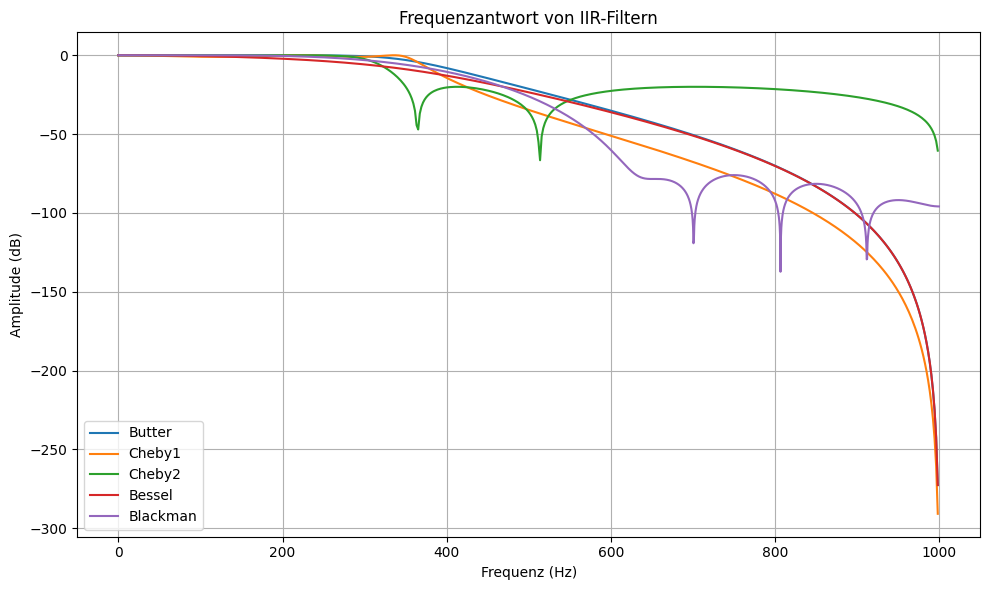

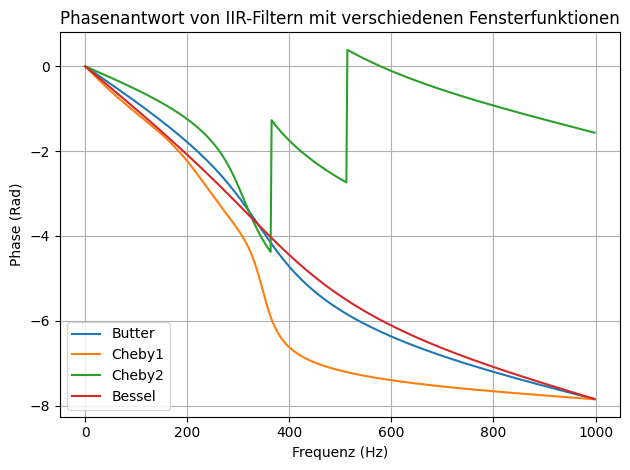

In [4]:
# Parameter
fc = 350       # Grenzfrequenz in Hz
order = 5     # Filterordnung
fs = 2000      # Abtastfrequenz in Hz

# Fensterarten
iir_types = ['butter', 'cheby1', 'cheby2', 'bessel']

# Diagramm vorbereiten
plt.figure(figsize=(10, 6))

# Frequenzantwort für jedes Fenster berechnen und darstellen
for iir_type in iir_types:
    if iir_type == 'butter':
        b, a = signal.butter(order, fc, fs=fs, btype='low')
    elif iir_type == 'cheby1':
        b, a = signal.cheby1(order, 1, fc, fs=fs, btype='low')
    elif iir_type == 'cheby2':
        b, a = signal.cheby2(order, 20, fc, fs=fs, btype='low')
    elif iir_type == 'bessel':
        b, a = signal.bessel(order, fc, fs=fs, btype='low', norm='phase')
    else:
        continue
    #Calculate the frequency response of the filter
    w, h = signal.freqz(b, a, fs=fs)
    plt.plot(w, 20 * np.log10(np.abs(h)), label=iir_type.capitalize())

b = firwin(20 + 1, fc, window= 'blackman', fs=fs)
w, h = freqz(b, worN=2000, fs=fs)
plt.plot(w, 20 * np.log10(np.abs(h)), label=window_type.capitalize())

# Diagramm formatieren
plt.title('Frequenzantwort von IIR-Filtern')
plt.xlabel('Frequenz (Hz)')
plt.ylabel('Amplitude (dB)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Phasenantwort für jedes Fenster berechnen und darstellen
for iir_type in iir_types:
    if iir_type == 'butter':
        b, a = signal.butter(order, fc, fs=fs, btype='low')
    elif iir_type == 'cheby1':
        b, a = signal.cheby1(order, 1, fc, fs=fs, btype='low')
    elif iir_type == 'cheby2':
        b, a = signal.cheby2(order, 20, fc, fs=fs, btype='low')
    elif iir_type == 'bessel':
        b, a = signal.bessel(order, fc, fs=fs, btype='low', norm='phase')
    else:
        continue
    #Calculate the frequency response of the filter
    w, h = signal.freqz(b, a, fs=fs)
    plt.plot(w, np.unwrap(np.angle(h)), label=f'{iir_type.capitalize()}')



# Diagramm formatieren
plt.title('Phasenantwort von IIR-Filtern mit verschiedenen Fensterfunktionen')
plt.xlabel('Frequenz (Hz)')
plt.ylabel('Phase (Rad)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## FIR vs IIR Filter

| **Merkmal**                 | **FIR-Filter**                                     | **IIR-Filter**                                     |
|-----------------------------|---------------------------------------------------|---------------------------------------------------|
| **Phasenverhalten**         | Linear (keine Phasenverzerrung)                   | Nicht-linear (kann Phasenverzerrung verursachen)  |
| **Stabilität**              | Immer stabil (keine Rückkopplung)                 | Kann instabil sein (verwendet Rückkopplung)       |
| **Recheneffizienz**         | Weniger effizient (höherer Filtergrad erforderlich) | Effizienter (erreicht Ergebnisse mit niedrigerem Filtergrad) |
| **Speicherbedarf**          | Höher (mehr Koeffizienten erforderlich)           | Niedriger (weniger Koeffizienten erforderlich)    |
| **Übergangsbereich**        | Langsamer Übergang (mehr Koeffizienten nötig)     | Schärferer Übergang (mit weniger Koeffizienten erreichbar) |
| **Empfindlichkeit gegenüber Quantisierung** | Weniger empfindlich (besser für Festkomma-Systeme geeignet) | Empfindlicher (anfällig für Rundungs-/Quantisierungsfehler) |
| **Rückkopplung**            | Keine Rückkopplung                                | Verwendet Rückkopplung                            |
| **Design-Komplexität**      | Einfacher zu entwerfen                            | Komplexer zu entwerfen (insbesondere für Stabilität) |
| **Anwendungen**             | Ideal für phasenkritische Anwendungen (z. B. Audio, Kommunikation) | Ideal für ressourcenbeschränkte Systeme oder zur Nachbildung analoger Filter |
| **Mathematische Operation**   | Faltung | Rekursion |



**📝  Aufgabe 4: Signal filtern**
Gegeben ist ein Signal mit zwei Sinusschwingungen. Filtere es mit der angegebenen Liste von Filtern und zeige den ersten Zyklus des gefilterten Signals. Stelle die erste Periode aller gefilterten Signale zusammen mit dem Originalsignal dar. Was passiert dabei?

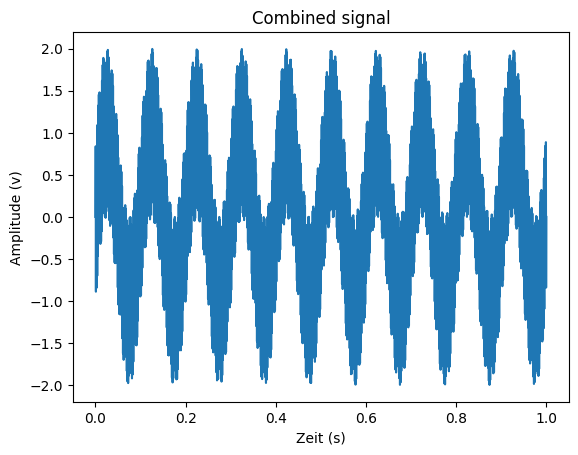

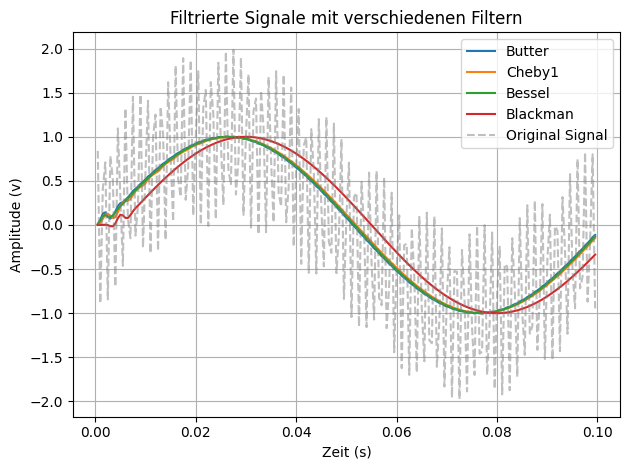

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import firwin, freqz
from scipy.signal.windows import get_window
# Parameter
fc = 350       # Grenzfrequenz in Hz
order = 5     # Filterordnung
fs = 2000      # Abtastfrequenz in Hz
t_min = 0
t_max = 1
t1 = np.linspace(t_min, t_max, fs)
n = len(t1)
#Define the signal
f1 = 10
f2 = 700
input_signal = np.sin(2*np.pi*f1*t1)  + np.sin(2*np.pi*f2*t1) 
plt.plot(t1, input_signal)
plt.xlabel('Zeit (s)')
plt.ylabel('Amplitude (v)')
plt.title('Combined signal')
plt.show()

filter_types = ['butter', 'cheby1', 'bessel', 'blackman']

# Frequenzantwort für jedes Fenster berechnen und darstellen
for filter_type in filter_types:
    if filter_type == 'butter':
        b, a = signal.butter(order, fc, fs=fs, btype='low')
        w, h = signal.freqz(b, a, fs=fs)
        output = signal.lfilter(b, a, input_signal)        
    elif filter_type == 'blackman':
       b = firwin(20 + 1, fc, window= 'blackman', fs=fs)
       w, h = freqz(b, worN=2000, fs=fs)
       output = signal.lfilter(b, 1, input_signal)
    elif filter_type == 'cheby1':
        b, a = signal.cheby1(order, 1, fc, fs=fs, btype='low')
        w, h = signal.freqz(b, a, fs=fs)
        output = signal.lfilter(b, a, input_signal)
    elif filter_type == 'bessel':
        b, a = signal.bessel(order, fc, fs=fs, btype='low', norm='phase')
        w, h = signal.freqz(b, a, fs=fs)
        output = signal.lfilter(b, a, input_signal)
    else:
        continue
    #Calculate the frequency response of the filter
    plt.plot(t1[1:200], output[1:200], label=filter_type.capitalize()) 
   
# Diagramm formatieren
plt.plot(t1[1:200], input_signal[1:200], linestyle='--', color='grey', label='Original Signal', alpha=0.5)
plt.title('Filtrierte Signale mit verschiedenen Filtern')
plt.xlabel('Zeit (s)')
plt.ylabel('Amplitude (v)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Group delay vs Phase Delay

Warum zeigt der Blackman-Filter die größte Verzögerung?

Der Blackman-Filter ist ein FIR-Filter (Finite Impulse Response), der eine lineare Phasenverschiebung hat. Das bedeutet:

- Er verzögert alle Frequenzen um einen konstanten Wert → Gruppenlaufzeit = (N-1)/2 Abtastwerte.

- Bei deinem Filter mit Order = 20 beträgt die Verzögerung 10 Samples.

Im Vergleich dazu:

- IIR-Filter (Butterworth, Chebyshev, Bessel) haben keine konstante Gruppenlaufzeit.

- Sie verursachen Phasenverzerrungen. Die Phasenverzerrung ist besonders im Bereich der Grenzfrequenz (Cutoff-Frequenz) sichtbar.

Wie lässt sich das lösen?

**Zero-phase Filterung:** Mit filtfilt() wird diese Verzerrung rückgängig gemacht.

Teilweise übersetzt und basierend auf : https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.remez.html und https://www.infocusp.com/blogs/digital-filter-design-using-python/